# Plumeria_wd: a one-dimensional model for wind-driven volcanic plumes.

### First, we must import all the python packages we need.

In [7]:
import sys
import pandas as pd

### Now, please specify the name of the output file you want the data to be exported to, as well as if you are including a atmospheric data file.

In [18]:
output_file = "shared-readwrite/Models/plumeria_wd/example_output/HTHH_output_alpha0.15.txt"

include_atmo = True

atmo_file = "metfile.txt"

### If you are not including an atmospheric data file, please enter the tropospheric properties below. Otherwise, this cell can be ignored.

In [4]:
#Air temperature at vent, Celsius.
air_temp = 0
#Air relative humidity
air_rel_hum = 100
#thermal lapse rate in troposphere (K/m upward--should be negative)
tlr_tropo = -.0065
#Elevation of tropopause (m asl)
elevation_tropo = 11000
#Tropopause isothermal layer thickness, m
isotherm = 9000
#thermal lapse rate in stratosphere (K/m--should be positive)
tlr_strato = .001
#wind speed, m/s, direction (deg. CW from N)
wind_speed, wind_direction = 0, 90

### Next, please specify some vent properties.

In [5]:
#Vent elevation (m asl)
vent_elevation = 144
#vent diameter (m)
vent_diam = 5114
#exit velocity (m/s)
exit_velocity = 71
#mass fraction added water, water temperature (100=steam)
mfad, water_temp = .9, 100

### Finally, we must specify some magma properties.

In [6]:
#magma temperature
magma_temp = 1050
#mass fraction gas in magma
mass_frac_gas = .03
#magma specific heat, J/kg K
sp_h = 1100
#magma density (DRE), kg/m3
magma_dre = 2500

In [ ]:
inp = f"""i#  Input file for the Fortran version of Plumeria.
#  Lines that begin with a # are comment lines.
#
#  Output file name
{output_file}
#
#  Information on whether to read met. input file.
#  The first line should supply a "yes" or "no".  If that line is "yes", the next line
#  should be the name of the input file used.
{"yes" if include_atmo else "no"}
{atmo_file}
#
#  Tropospheric properties (used only if no atmospheric file is used)
#
{air_temp}                   #Air temperature at vent, Celsius.
{air_rel_hum}                 #Air relative humidity
{tlr_tropo}              #thermal lapse rate in troposphere (K/m upward--should be negative)
{elevation_tropo}               #Elevation of tropopause (m asl)
{isotherm}                #Tropopause isothermal layer thickness, m
{tlr_strato}                #thermal lapse rate in stratosphere (K/m--should be positive)
{wind_speed}  {wind_direction}          #wind speed, m/s, direction (deg. CW from N)
#
#  Vent properties
#
{vent_elevation}                #Vent elevation (m asl)
{vent_diam}               #vent diameter (m)
{exit_velocity}                 #exit velocity (m/s)
{mass_frac_gas}  {water_temp}          #mass fraction added water, water temperature (100=steam)
#
#   Magma properties
#
{magma_temp}                #magma temperature
{mass_frac_gas}                 #mass fraction gas in magma
{sp_h}                #magma specific heat, J/kg K
{magma_dre}                #magma density (DRE), kg/m3
#
#   Other properties (optional)
#
0.15,  0.50, 1.0     #entrainment coefficients (radial, wind), n_exp
"""
f = open("input.py","w")
f.write(inp)
f.close()

In [70]:
f = open(output_file, 'r+')
lines = f.readlines()
word = '***'  # String to search for
if row.find(word) == -1:
    break
else:
    idx = []
    for row in lines:
            word = '***'  # String to search for
            if row.find(word) != -1:
                idx.append(lines.index(row))
    lines = lines[idx[0]+1:idx[1]]
    head, units = lines[0].split(), lines[1].split()
    units.insert(0, ' ')
    units.insert(4, ' ')
    units.insert(4, ' ')
    units.insert(4, ' ')
    units.insert(4, ' ')
    units.insert(4, ' ')
    
    result = [a + " (" + b + ")" for a, b in zip(head, units)]
    lines = lines[2:]
    lines
    f.seek(0)
    f.writelines(lines)
    f.truncate()
    f.close()

In [72]:
df = pd.read_fwf(output_file,header=None)

In [73]:
df.columns = result
df

,i ( ),s (meters),z (meters),x (meters),y ( ),m_m ( ),m_a ( ),m_w ( ),m_l ( ),m_i (meters),...,u (m/s),r (m),T_mix (Kelvin),T_air (Kelvin),rho_mix (kg/m3),rho_air (kg/m3),Time (seconds),p_air (Pa),water (g/m3),ice (g/m3)
0,1,0.0,0.0,0.0,0.0,0.09690,0.00100,0.902,0.0,0.000,...,71.00,2557.0,433.3,299.7,0.547,1.148,0.0,98721.4,0.0,0.000
1,2,1.0,1.0,-0.0,0.0,0.09690,0.00131,0.902,0.0,0.000,...,71.13,2555.0,433.2,299.7,0.547,1.148,0.0,98710.1,0.0,0.000
2,3,2.5,2.5,-0.0,0.0,0.09680,0.00177,0.901,0.0,0.000,...,71.32,2552.0,433.2,299.7,0.547,1.148,0.0,98693.2,0.0,0.000
3,4,4.6,4.6,-0.0,0.0,0.09680,0.00241,0.901,0.0,0.000,...,71.59,2547.9,433.1,299.7,0.547,1.147,0.1,98669.8,0.0,0.000
4,5,7.3,7.3,-0.0,0.0,0.09670,0.00323,0.900,0.0,0.000,...,71.93,2542.7,433.0,299.6,0.547,1.147,0.1,98639.5,0.0,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5539,540,276.3,261.5,35.9,4.9,0.00671,0.92900,0.064,0.0,0.064,...,13.51,8294.1,179.9,259.3,0.005,0.003,5.5,229.4,0.0,0.306
5540,541,284.0,269.1,34.6,5.4,0.00671,0.92900,0.064,0.0,0.064,...,11.39,9620.5,179.8,259.3,0.005,0.003,6.1,229.2,0.0,0.306
5541,542,291.7,276.6,32.8,5.9,0.00671,0.92900,0.064,0.0,0.064,...,8.79,5579.1,179.8,259.3,0.005,0.003,6.9,228.9,0.0,0.306
5542,543,298.4,282.8,30.8,6.6,0.00671,0.92900,0.064,0.0,0.064,...,5.80,3959.2,179.8,259.3,0.005,0.003,7.8,228.8,0.0,0.305


<Axes: >

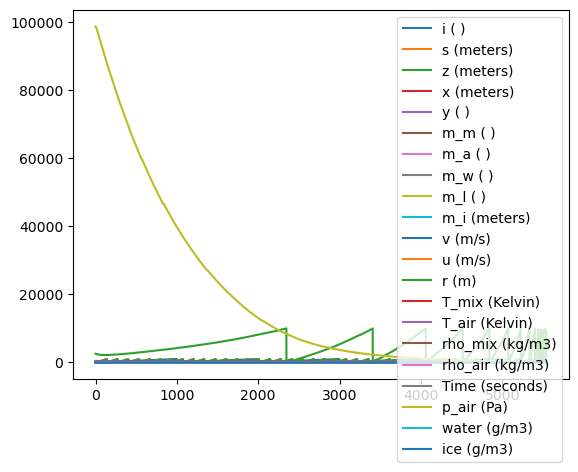

In [75]:
df.plot()